# Matplotlib: trực quan hóa dữ liệu

Vẽ biểu đồ là bước đầu tiên để hiểu dữ liệu trước khi xây dựng mô hình. Dùng lại dữ liệu sinh viên ở notebook trước.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'
df = pd.read_csv(DATA / 'students.csv')

## 1. Đồ thị đường: vẽ một hàm số

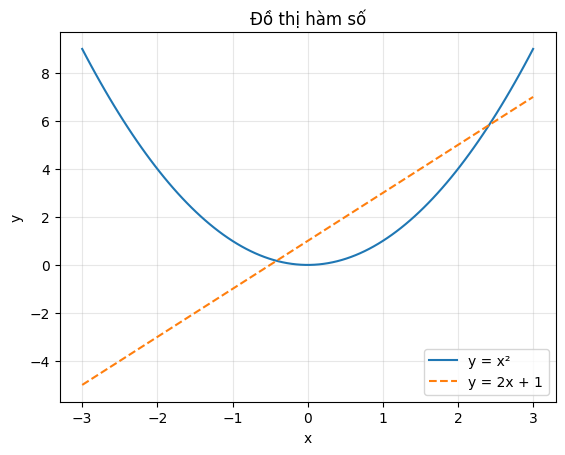

In [2]:
x = np.linspace(-3, 3, 100)          # 100 điểm trên trục hoành
plt.plot(x, x**2, label='y = x²')
plt.plot(x, 2 * x + 1, '--', label='y = 2x + 1')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Đồ thị hàm số')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 2. Biểu đồ phân tán: quan hệ giữa hai đặc trưng

Mỗi điểm là một sinh viên, màu thể hiện nhãn. Hai nhóm nằm ở hai vùng khá tách biệt: đây là dấu hiệu một mô hình phân loại có thể học được từ hai đặc trưng này.

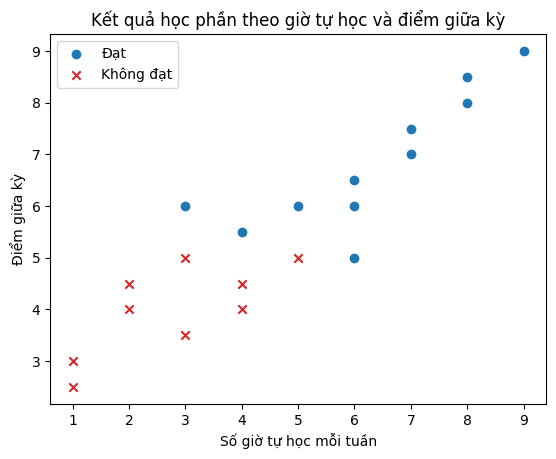

In [3]:
passed = df[df['passed'] == 1]       # nhóm đạt
failed = df[df['passed'] == 0]       # nhóm không đạt

plt.scatter(passed['study_hours'], passed['midterm'], c='tab:blue', marker='o', label='Đạt')
plt.scatter(failed['study_hours'], failed['midterm'], c='tab:red', marker='x', label='Không đạt')
plt.xlabel('Số giờ tự học mỗi tuần')
plt.ylabel('Điểm giữa kỳ')
plt.title('Kết quả học phần theo giờ tự học và điểm giữa kỳ')
plt.legend()
plt.show()

## 3. Biểu đồ tần suất (histogram) và nhiều hình con

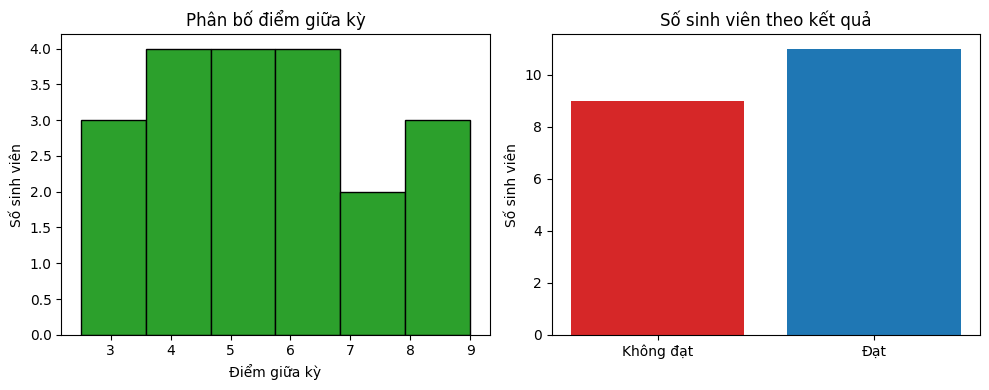

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # 1 hàng, 2 hình con

axes[0].hist(df['midterm'], bins=6, color='tab:green', edgecolor='black')
axes[0].set_xlabel('Điểm giữa kỳ')
axes[0].set_ylabel('Số sinh viên')
axes[0].set_title('Phân bố điểm giữa kỳ')

counts = df['passed'].value_counts().sort_index()   # số sinh viên không đạt (0), đạt (1)
axes[1].bar(['Không đạt', 'Đạt'], counts.values, color=['tab:red', 'tab:blue'])
axes[1].set_ylabel('Số sinh viên')
axes[1].set_title('Số sinh viên theo kết quả')

fig.tight_layout()
plt.show()